In [1]:
import sys
import os
import joblib
import pandas as pd
from sklearn.preprocessing import StandardScaler
sys.path.append(os.path.abspath(".."))
from utils.base_model import *

In [2]:
data = joblib.load("../artifacts/processed_data.pkl")
X_train = data["X_train_res"]
y_train = data["y_train_res"]
X_val   = data["X_val_scaled"]
y_val   = data["y_val"]
X_test  = data["X_test_scaled"]
y_test  = data["y_test"]
feature_names = data["feature_names"]

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (42732, 16) | Val: (4526, 16) | Test: (29538, 16)


# Logistic Regression

TRAIN

In [3]:
log_model = train_model(X_train, y_train, model_type="logistic", C=0.5, max_iter=600)


>>> Đang train mô hình: LOGISTIC...


c:\Users\jason\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


>>> Đã train xong: LOGISTIC!


VALIDATION

In [4]:
val_proba_log = predict_proba_pos(log_model, X_val)
best_th_log, th_df_log = find_best_threshold(y_val, val_proba_log, metric="f1")

Best threshold theo f1: 0.70


EVAL

In [5]:
test_proba_log = predict_proba_pos(log_model, X_test)
res_log = evaluate_model(y_test, test_proba_log, threshold=best_th_log, title="LOGISTIC REGRESSION")

===== LOGISTIC REGRESSION (THRESHOLD = 0.70) =====
Accuracy : 0.9249
Precision: 0.7057
Recall   : 0.8197
F1-score : 0.7584
ROC-AUC  : 0.9573
PR-AUC   : 0.834

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.96     25290
           1       0.71      0.82      0.76      4248

    accuracy                           0.92     29538
   macro avg       0.84      0.88      0.86     29538
weighted avg       0.93      0.92      0.93     29538



PLOT

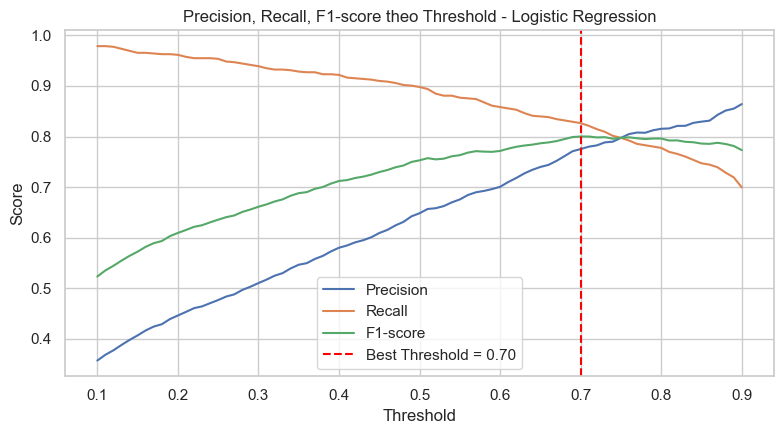

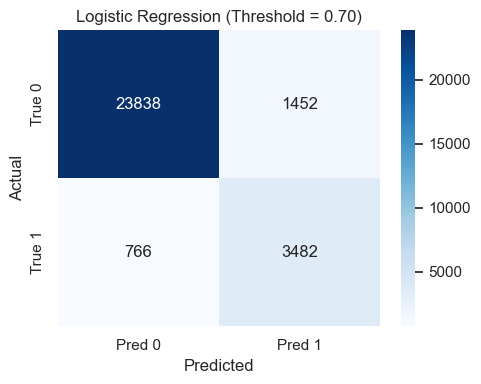

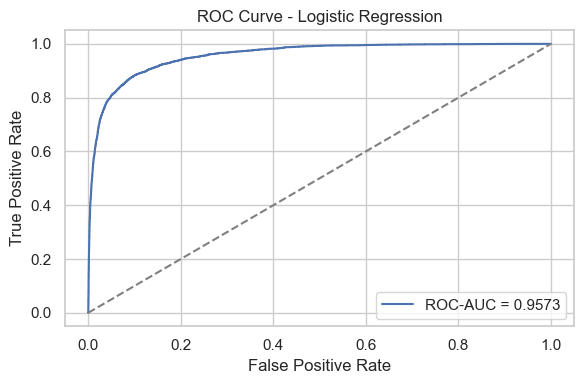

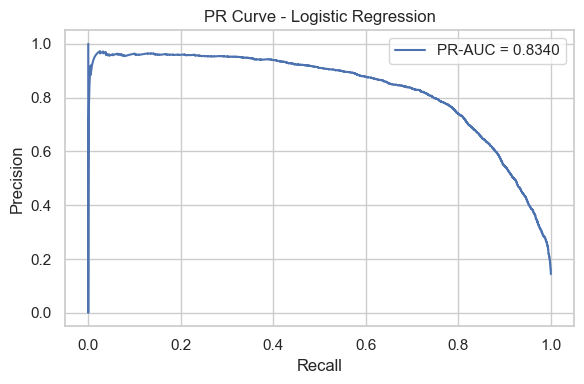

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


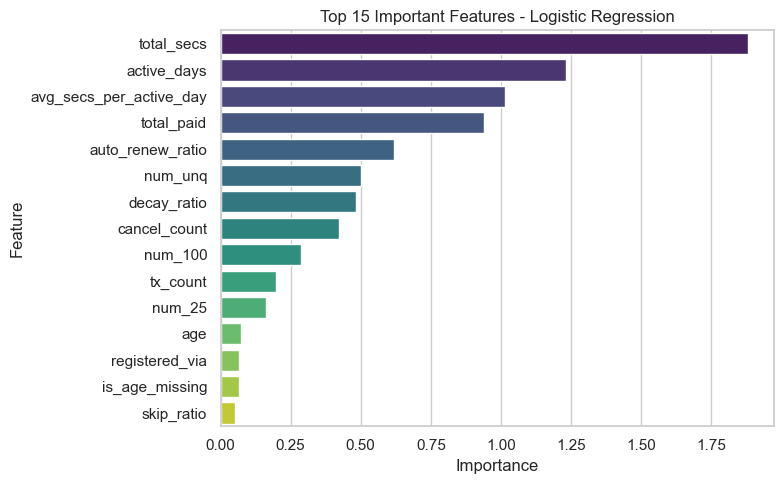

,feature,importance
1,total_secs,1.879568
0,active_days,1.232450
14,avg_secs_per_active_day,1.014312
9,total_paid,0.939907
10,auto_renew_ratio,0.619683
4,num_unq,0.499579
12,decay_ratio,0.482196
11,cancel_count,0.424047
2,num_100,0.286155
8,tx_count,0.196813


In [6]:
plot_threshold_metrics(th_df_log, best_th_log, title="Logistic Regression")
plot_confusion_matrix_custom(y_test, test_proba_log, threshold=best_th_log, title="Logistic Regression")
plot_roc_curve_custom(y_test, test_proba_log, title="ROC Curve - Logistic Regression")
plot_pr_curve_custom(y_test, test_proba_log, title="PR Curve - Logistic Regression")
plot_feature_importance(log_model, feature_names, title="Logistic Regression")

SAVE

In [7]:
save_model(log_model, "../artifacts/logistic_model.pkl", "../artifacts/logistic_info.pkl", best_th_log, feature_names, model_type="logistic_regression")

Đã lưu model: ../artifacts/logistic_model.pkl
Đã lưu model info: ../artifacts/logistic_info.pkl


# Mock test

In [ ]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_log 
pred_proba = predict_proba_pos(log_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])

# DECISION TREE

TRAIN

In [8]:
dt_model = train_model(X_train, y_train, model_type="decision_tree", max_depth=8, min_samples_split=20)


>>> Đang train mô hình: DECISION_TREE...
>>> Đã train xong: DECISION_TREE!


VALIDATION

In [9]:
val_proba_dt = predict_proba_pos(dt_model, X_val)
best_th_dt, th_df_dt = find_best_threshold(y_val, val_proba_dt, metric="f1")

Best threshold theo f1: 0.66


EVAL

In [10]:
test_proba_dt = predict_proba_pos(dt_model, X_test)
res_dt = evaluate_model(y_test, test_proba_dt, threshold=best_th_dt, title="DECISION TREE")

===== DECISION TREE (THRESHOLD = 0.66) =====
Accuracy : 0.9283
Precision: 0.7198
Recall   : 0.8211
F1-score : 0.7671
ROC-AUC  : 0.9508
PR-AUC   : 0.8177

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96     25290
           1       0.72      0.82      0.77      4248

    accuracy                           0.93     29538
   macro avg       0.84      0.88      0.86     29538
weighted avg       0.93      0.93      0.93     29538



PLOT

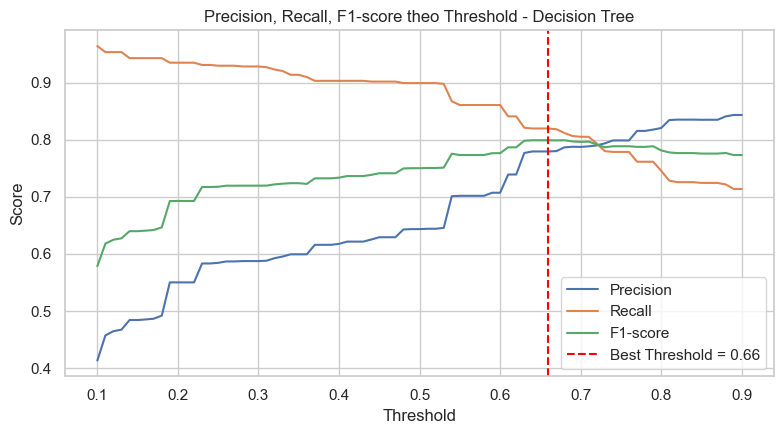

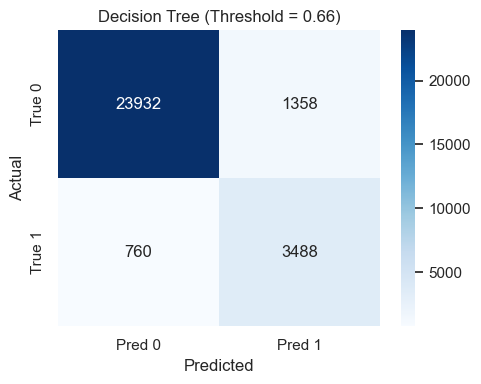

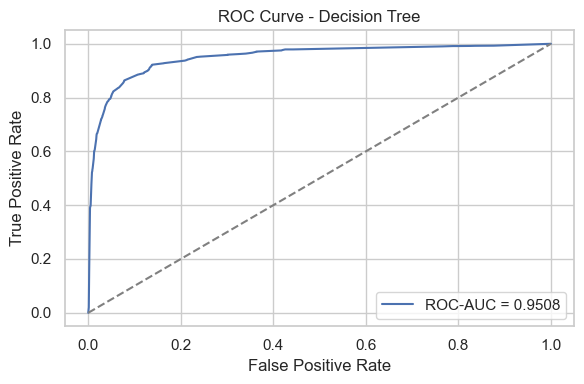

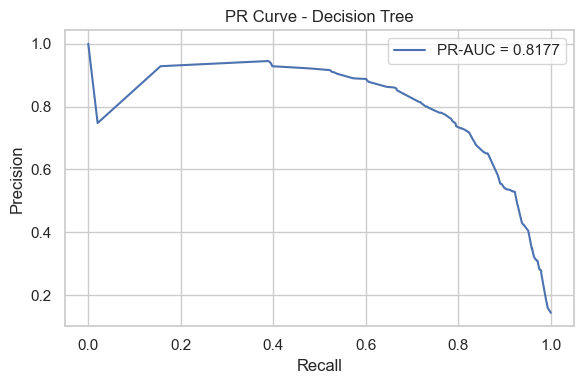

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


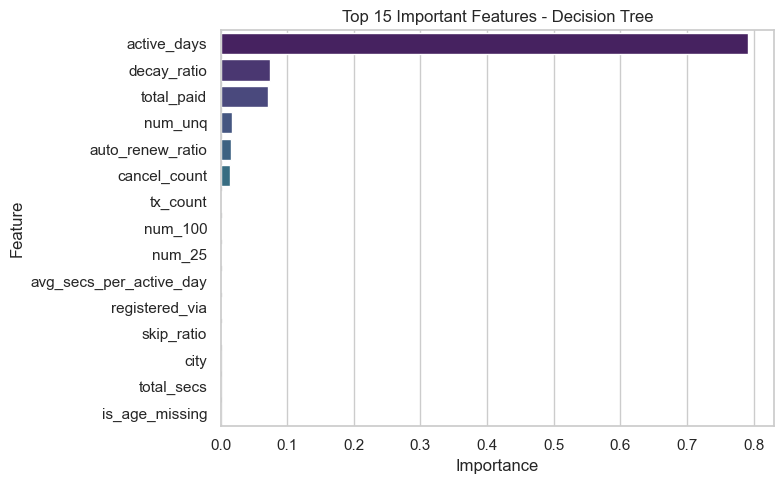

,feature,importance
0,active_days,0.791196
12,decay_ratio,0.073898
9,total_paid,0.071132
4,num_unq,0.017096
10,auto_renew_ratio,0.015809
11,cancel_count,0.014741
8,tx_count,0.002365
2,num_100,0.002257
3,num_25,0.002005
14,avg_secs_per_active_day,0.001995


In [11]:
plot_threshold_metrics(th_df_dt, best_th_dt, title="Decision Tree")
plot_confusion_matrix_custom(y_test, test_proba_dt, threshold=best_th_dt, title="Decision Tree")
plot_roc_curve_custom(y_test, test_proba_dt, title="ROC Curve - Decision Tree")
plot_pr_curve_custom(y_test, test_proba_dt, title="PR Curve - Decision Tree")
plot_feature_importance(dt_model, feature_names, title="Decision Tree")

SAVE

In [12]:
save_model(dt_model, "../artifacts/decision_tree_model.pkl", "../artifacts/decision_tree_info.pkl", best_th_dt, feature_names, model_type="decision_tree")

Đã lưu model: ../artifacts/decision_tree_model.pkl
Đã lưu model info: ../artifacts/decision_tree_info.pkl


In [46]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_dt
pred_proba = predict_proba_pos(dt_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])


===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====


,Status,Churn_Probability,active_days,total_secs,num_100,num_25,num_unq
0,Stay,0.0015,30,250000,0,0.05,1
1,Leave,1.0000,2,5000,1,0.85,0
2,Stay,0.0235,15,120000,0,0.20,1
3,Stay,0.5857,1,1200,2,0.95,0
4,Stay,0.0174,28,300000,0,0.02,1


# RANDOM FOREST

TRAIN

In [13]:
rf_model = train_model(X_train, y_train, model_type="random_forest", n_estimators=200, max_depth=12)


>>> Đang train mô hình: RANDOM_FOREST...
>>> Đã train xong: RANDOM_FOREST!


VALIDATION

In [14]:
val_proba_rf = predict_proba_pos(rf_model, X_val)
best_th_rf, th_df_rf = find_best_threshold(y_val, val_proba_rf, metric="f1")

Best threshold theo f1: 0.63


EVAL

In [15]:
test_proba_rf = predict_proba_pos(rf_model, X_test)
res_rf = evaluate_model(y_test, test_proba_rf, threshold=best_th_rf, title="RANDOM FOREST")

===== RANDOM FOREST (THRESHOLD = 0.63) =====
Accuracy : 0.9359
Precision: 0.7627
Recall   : 0.8048
F1-score : 0.7832
ROC-AUC  : 0.9646
PR-AUC   : 0.8595

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96     25290
           1       0.76      0.80      0.78      4248

    accuracy                           0.94     29538
   macro avg       0.86      0.88      0.87     29538
weighted avg       0.94      0.94      0.94     29538



PLOT

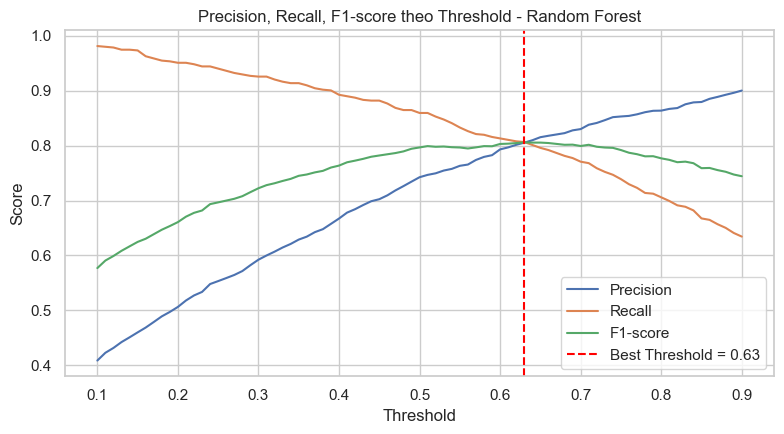

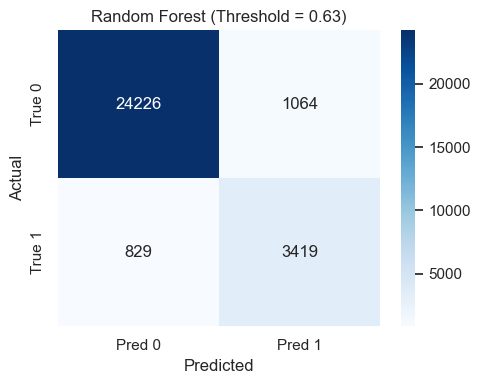

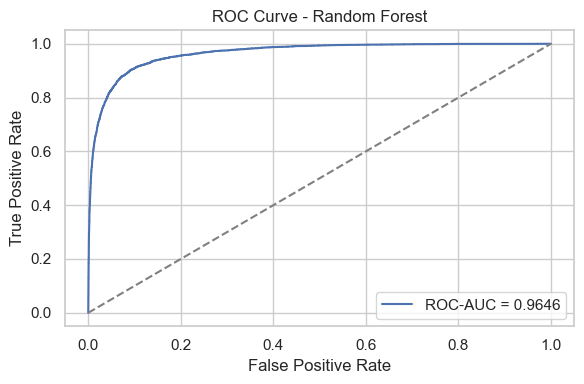

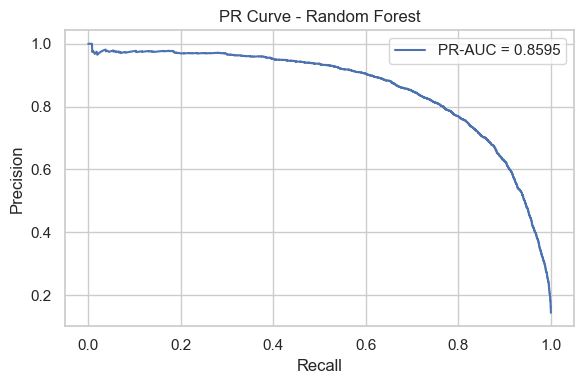

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


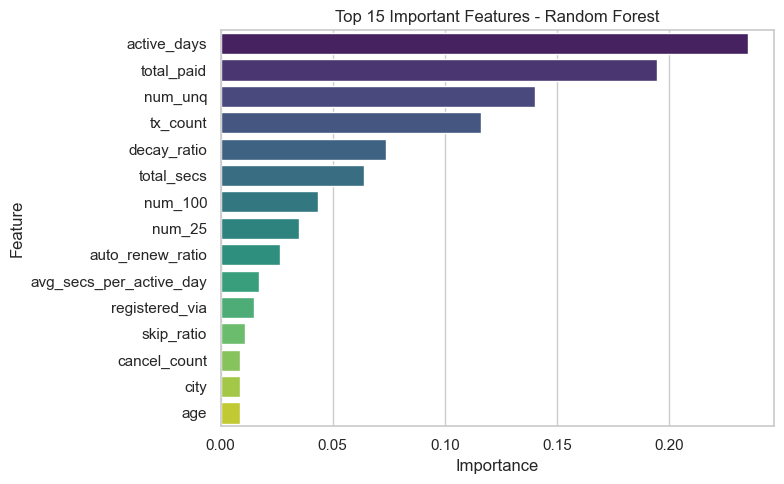

,feature,importance
0,active_days,0.234856
9,total_paid,0.194650
4,num_unq,0.140152
8,tx_count,0.116066
12,decay_ratio,0.073772
1,total_secs,0.063848
2,num_100,0.043603
3,num_25,0.034814
10,auto_renew_ratio,0.026497
14,avg_secs_per_active_day,0.017167


In [16]:
plot_threshold_metrics(th_df_rf, best_th_rf, title="Random Forest")
plot_confusion_matrix_custom(y_test, test_proba_rf, threshold=best_th_rf, title="Random Forest")
plot_roc_curve_custom(y_test, test_proba_rf, title="ROC Curve - Random Forest")
plot_pr_curve_custom(y_test, test_proba_rf, title="PR Curve - Random Forest")
plot_feature_importance(rf_model, feature_names, title="Random Forest")

SAVE

In [17]:
save_model(rf_model, "../artifacts/random_forest_model.pkl", "../artifacts/random_forest_info.pkl",
           best_th_rf, feature_names, model_type="random_forest")

Đã lưu model: ../artifacts/random_forest_model.pkl
Đã lưu model info: ../artifacts/random_forest_info.pkl


In [47]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_rf 
pred_proba = predict_proba_pos(rf_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])


===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====


,Status,Churn_Probability,active_days,total_secs,num_100,num_25,num_unq
0,Stay,0.2980,30,250000,0,0.05,1
1,Stay,0.6122,2,5000,1,0.85,0
2,Stay,0.3437,15,120000,0,0.20,1
3,Leave,0.6994,1,1200,2,0.95,0
4,Stay,0.2888,28,300000,0,0.02,1


# XG BOOST

TRAIN

In [18]:
scale_pos_weight = cal_scale_pos_weight(y_train)

Negative (0): 21,366 | Positive (1): 21,366
scale_pos_weight: 1.00


In [19]:
xgb_model = train_model(
    X_train, y_train,
    model_type="xgboost",
    scale_pos_weight=scale_pos_weight,
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03
)


>>> Đang train mô hình: XGBOOST...
>>> Đã train xong: XGBOOST!


VALIDATION

In [20]:
val_proba_xgb = predict_proba_pos(xgb_model, X_val)
best_th_xgb, th_df_xgb = find_best_threshold(y_val, val_proba_xgb, metric="f1")

Best threshold theo f1: 0.61


EVAL

In [21]:
test_proba_xgb = predict_proba_pos(xgb_model, X_test)
res_xgb = evaluate_model(y_test, test_proba_xgb, threshold=best_th_xgb, title="XGBOOST")

===== XGBOOST (THRESHOLD = 0.61) =====
Accuracy : 0.939
Precision: 0.7814
Recall   : 0.7994
F1-score : 0.7903
ROC-AUC  : 0.965
PR-AUC   : 0.8646

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96     25290
           1       0.78      0.80      0.79      4248

    accuracy                           0.94     29538
   macro avg       0.87      0.88      0.88     29538
weighted avg       0.94      0.94      0.94     29538



PLOT

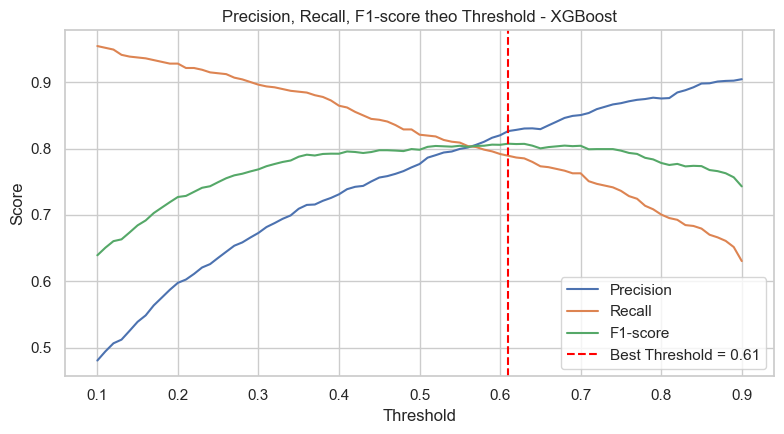

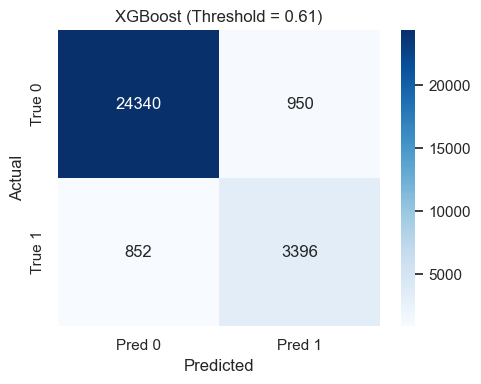

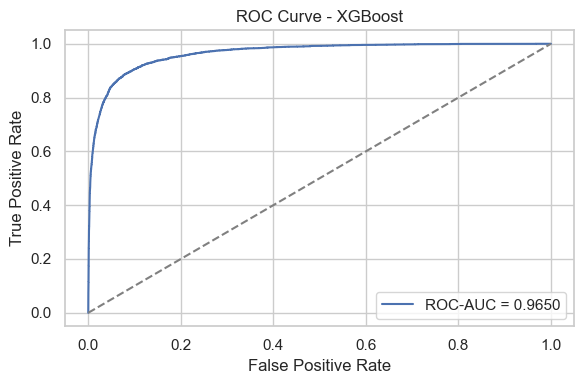

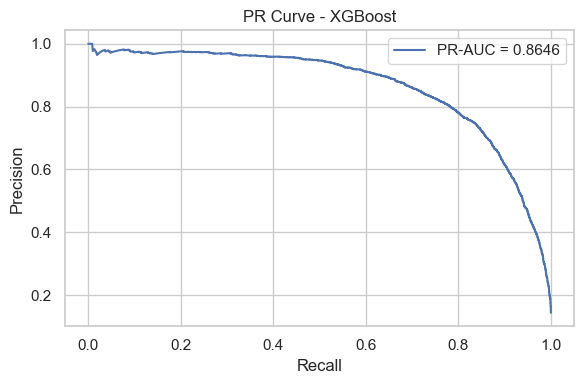

d:\Final_Project\utils\base_model.py:246: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="importance", y="feature", palette="viridis")


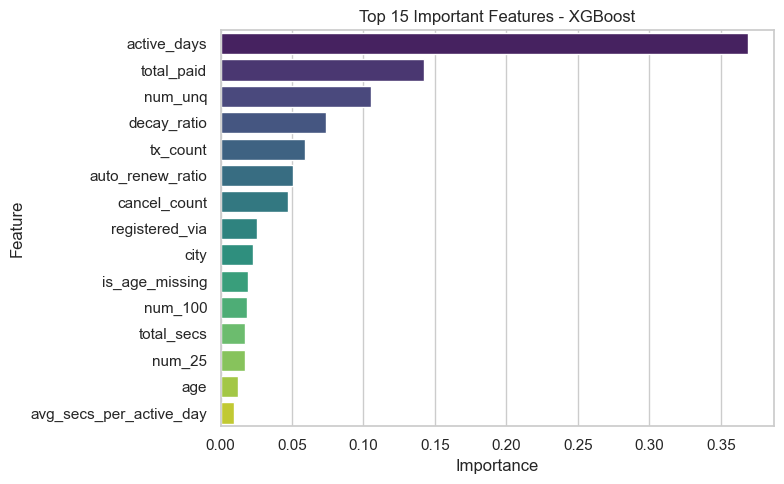

,feature,importance
0,active_days,0.368741
9,total_paid,0.142104
4,num_unq,0.105488
12,decay_ratio,0.073947
8,tx_count,0.059446
10,auto_renew_ratio,0.051010
11,cancel_count,0.047336
7,registered_via,0.025611
5,city,0.022887
15,is_age_missing,0.019325


In [22]:
plot_threshold_metrics(th_df_xgb, best_th_xgb, title="XGBoost")
plot_confusion_matrix_custom(y_test, test_proba_xgb, threshold=best_th_xgb, title="XGBoost")
plot_roc_curve_custom(y_test, test_proba_xgb, title="ROC Curve - XGBoost")
plot_pr_curve_custom(y_test, test_proba_xgb, title="PR Curve - XGBoost")
plot_feature_importance(xgb_model, feature_names, title="XGBoost")

SAVE

In [23]:
save_model(xgb_model, "../artifacts/xgboost_model.pkl", "../artifacts/xgboost_info.pkl",
           best_th_xgb, feature_names, model_type="xgboost", scale_pos_weight=scale_pos_weight)

Đã lưu model: ../artifacts/xgboost_model.pkl
Đã lưu model info: ../artifacts/xgboost_info.pkl


In [ ]:
manual_data = [
    [30, 250000, 0, 0.05, 1, 0, 25, 1, 1, 0, 5, 2, 10, 0, 1, 0, 12, 1],
    [2, 5000, 1, 0.85, 0, 1, 45, 0, 0, 1, 45, 12, 0, 1, 0, 2, 2, 0],
    [15, 120000, 0, 0.20, 1, 0, 30, 1, 1, 0, 15, 4, 5, 0, 1, 0, 6, 1],
    [1, 1200, 2, 0.95, 0, 1, 22, 0, 0, 1, 60, 20, 0, 1, 1, 0, 1, 0],
    [28, 300000, 0, 0.02, 1, 0, 35, 1, 1, 0, 2, 1, 15, 0, 1, 0, 24, 1],
]

X_manual_df = pd.DataFrame(manual_data, columns=feature_names)
scaler = StandardScaler()
scaler.fit(X_manual_df)

X_manual_scaled = scaler.transform(X_manual_df)
X_manual_input = pd.DataFrame(X_manual_scaled, columns=feature_names)


current_best_threshold = best_th_xgb 
pred_proba = predict_proba_pos(xgb_model, X_manual_input)
pred_labels = (pred_proba >= current_best_threshold).astype(int)

# 5. Gắn kết quả vào bảng dữ liệu gốc để quan sát
X_manual_df["Churn_Probability"] = np.round(pred_proba, 4)
X_manual_df["Status"] = ["Leave" if label == 1 else "Stay" for label in pred_labels]

print(f"\n===== KẾT QUẢ DỰ ĐOÁN 5 MẪU (ĐÃ SCALE) =====")
display(X_manual_df[["Status", "Churn_Probability"] + list(feature_names[:5])])

# COMPARISON

In [24]:
comparison_df = pd.DataFrame([
    {"Model": "Logistic Regression", **res_log},
    {"Model": "Decision Tree", **res_dt},
    {"Model": "Random Forest", **res_rf},
    {"Model": "XGBoost", **res_xgb},
]).sort_values(by="F1-score Class 1", ascending=False)

display(comparison_df)

,Model,Best Threshold,ROC-AUC,PR-AUC,Accuracy,Precision Class 1,Recall Class 1,F1-score Class 1
3,XGBoost,0.61,0.9650,0.8646,0.9390,0.7814,0.7994,0.7903
2,Random Forest,0.63,0.9646,0.8595,0.9359,0.7627,0.8048,0.7832
1,Decision Tree,0.66,0.9508,0.8177,0.9283,0.7198,0.8211,0.7671
0,Logistic Regression,0.70,0.9573,0.8340,0.9249,0.7057,0.8197,0.7584
